# 02 · Exploratory data analysis (EDA)

**EDA** means looking carefully at the data *before* modelling: how it is distributed, what is missing, what goes with what.
It answers two practical questions:
1. **What does the report's "Dataset Description and Analysis" section need to say?** Every chart here is saved for the report.
2. **What does it change in the modelling?** Each section ends with a short "so what" for Part B and the models.

It reads only the clean table made by `01_clean_table.ipynb`, so run that first.

| | |
|---|---|
| **Reads** | `data/clean/pisa6_clean.parquet`, `data/clean/columns.json` |
| **Writes** | figures to `02_data-analysis/outputs/eda/figures/`, the numbers behind every figure to `02_data-analysis/outputs/eda/*.csv` |

**How the numbers are computed** (the PISA rules from the README):
- **Within one system**, statistics use the student weight `W_FSTUWT`.
- **When the six systems are pooled**, we use `SENWT`, which makes every system count equally. Otherwise Morocco and Saudi Arabia (71% of the population weight) would dominate.
  Which weight the *models* use is still a team decision (Part B).
- Anything involving maths is computed **once per plausible value and averaged over all 10**.
- These are point estimates; standard errors (from the 80 replicate weights) are left for the final results tables.
- Everything here is an **association, not a cause**.

> **AI-use note.** The code in this notebook was generated by an AI assistant (Claude Code, Anthropic, model Claude Opus 5.5) on 17 Nov 2026,
> from the prompt *"Start the EDA notebook"* (choosing the next step after Part A).
> That continues the task set by the prompts quoted in `01_clean_table.ipynb`, which asked for the preprocessing, cleanup and EDA.
> The variable names were then changed to follow the naming rules below, from the prompt
> *"for the notebooks already created, can we improve the var names? python is already hard as its not clear whther a var represents a list or a single value etc."*.
> The outputs did not change.

## How the variable names work

Python doesn't say what kind of thing a variable holds, so the **names** do. The same rules are used in every notebook in this folder.

| The name... | means it holds | Examples |
|---|---|---|
| is a singular word | **one** value | `system` = `"ARE"`, `feature` = `"ESCS"` |
| is a plural word | a **list** of values | `SYSTEMS` = `["ARE", "SAU", ...]` |
| ends in `_col` | **one** column name | `pv_col` = `"PV1MATH"`, `weight_col` = `"W_FSTUWT"` |
| ends in `_cols` | a **list** of column names | `PV_COLS` = `["PV1MATH", ..., "PV10MATH"]`, `FEATURE_COLS` |
| ends in `_df` | a **table** (a pandas DataFrame) | `students_df`, `system_df` (one system's students) |
| is just `df` | **the main table** of the notebook | |
| looks like `<value>_by_<key>` | a **lookup**: give it a key, get a value (a dict, or a pandas Series) | `FEATURES_BY_GROUP["family"]` gives the 4 family columns |
| starts with `is_` or `has_` | **True/False for each student**, used as a filter | `df[is_complete]` keeps the students with no blanks |
| starts with `n_` / `pct_` / `share_` | a count / a percentage (0-100) / a fraction (0-1) | `n_flagged_students`, `pct_missing_df`, `share_label_flips` |
| ends in `_idx` | a position (0, 1, 2, ...) | `row_idx` |
| ends in `_DIR` | a folder | `CLEAN_DIR`, `FIGURE_DIR` |
| ends in `_COLOR` / `_CMAP` | one colour / a colour scale | `TEXT_COLOR`, `BLUES_CMAP` |
| is in `UPPER_CASE` | a **fixed setting**, set once and never changed | `LEVEL2_CUTOFF`, `SYSTEMS` |
| is `fig`, `ax` or `axes` | a whole figure / one chart panel / several panels | matplotlib's usual names |

Loops use the singular of the list they walk through: `for system in SYSTEMS`, `for feature in FEATURE_COLS`.
Functions are named after what they return (`weighted_quantile()`) or what they do (`log_step()`, `draw_heatmap()`).
Each helper function has **type hints** saying what goes in and what comes out, e.g. `cols: list[str]` (a list of column names) and `-> float` (returns one number).

The column names *inside* the data (`ESCS`, `PV1MATH`, `W_FSTUWT`) are PISA's own. We don't rename them, so they still match the OECD documentation.

## Setup

The chart style is set once here: light background, thin marks, quiet grey axes. One colour (blue) is used whenever a chart shows a single thing.
Comparisons between the six systems use **small multiples** (one small panel per system, same axes) instead of six colours, so nobody has to match colours to a legend.

In [ ]:
from pathlib import Path
from collections.abc import Callable
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap, LinearSegmentedColormap, Normalize

ROOT = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "requirements.txt").exists())
df = pd.read_parquet(ROOT / "data/clean/pisa6_clean.parquet")
column_roles = json.loads((ROOT / "data/clean/columns.json").read_text())   # what each column is for
OUTPUT_DIR = ROOT / "02_data-analysis/outputs/eda"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:,.1f}".format)

SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
NAME_BY_SYSTEM = {"ARE": "UAE", "SAU": "Saudi Arabia", "QAT": "Qatar", "JOR": "Jordan", "MAR": "Morocco", "PSE": "Palestine"}
PV_COLS = column_roles["targets"]["regression"]             # PV1MATH ... PV10MATH
BELOW_L2_COLS = column_roles["targets"]["classification"]   # BELOW_L2_PV1 ... BELOW_L2_PV10
LEVEL2_CUTOFF = column_roles["targets"]["level2_cutoff"]    # 420.07
FEATURES_BY_GROUP = column_roles["feature_groups"]          # group name -> list of feature columns
FEATURE_COLS = [feature for group_cols in FEATURES_BY_GROUP.values() for feature in group_cols]   # all 17
LABEL_BY_FEATURE = {
    "ESCS": "Socio-economic status", "PAREDINT": "Parents' education", "HISEI": "Parents' occupation",
    "HOMEPOS": "Home possessions", "ANXMAT": "Maths anxiety", "MATHEFF": "Maths self-efficacy",
    "MATHEF21": "Self-efficacy (21st-c.)", "DISCLIM": "Disciplinary climate", "TEACHSUP": "Teacher support",
    "BELONG": "Sense of belonging", "BULLIED": "Being bullied", "EDUSHORT": "Material shortage",
    "STAFFSHORT": "Staff shortage", "MCLSIZE": "Maths class size", "STRATIO": "Student-teacher ratio",
    "SCHL_PRIVATE": "Private school", "SCHSIZE_log": "School size (log)",
}
LABEL_BY_GROUP = {"family": "Family", "maths_attitudes": "Attitudes", "classroom": "Classroom",
                  "climate_resources": "Climate & resources", "school_org": "School organisation"}
df_by_system = {system: df[df["CNT"] == system] for system in SYSTEMS}   # system code -> that system's students

# ---- chart style (reference palette, light mode) ----
BACKGROUND_COLOR = "#fcfcfb"
TEXT_COLOR, SOFT_TEXT_COLOR, MUTED_TEXT_COLOR = "#0b0b0b", "#52514e", "#898781"
GRID_COLOR, AXIS_COLOR = "#e1e0d9", "#c3c2b7"
CONTEXT_COLOR = "#d9d8d1"            # grey, for the other systems drawn behind the highlighted one
BLUE, ORANGE = "#2a78d6", "#eb6834"  # the first two colours of the palette
BLUES_CMAP = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])   # light -> dark blue
RED_BLUE_CMAP = LinearSegmentedColormap.from_list("red_blue", ["#e34948", "#f0efec", "#2a78d6"])   # red <-> grey <-> blue
plt.rcParams.update({
    "figure.facecolor": BACKGROUND_COLOR, "axes.facecolor": BACKGROUND_COLOR, "savefig.facecolor": BACKGROUND_COLOR,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "axes.edgecolor": AXIS_COLOR, "axes.linewidth": 0.8, "axes.labelcolor": SOFT_TEXT_COLOR,
    "axes.titlesize": 9.5, "axes.titleweight": "semibold", "axes.titlecolor": TEXT_COLOR, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "grid.color": GRID_COLOR, "grid.linewidth": 0.6,
    "xtick.color": AXIS_COLOR, "ytick.color": AXIS_COLOR, "xtick.labelcolor": SOFT_TEXT_COLOR, "ytick.labelcolor": SOFT_TEXT_COLOR,
    "text.color": TEXT_COLOR, "legend.frameon": False, "lines.linewidth": 1.6, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

# ---- weighted statistics ----
def weighted_quantile(values: pd.Series, weights: pd.Series, q: float) -> float:
    """The value below which a share q (between 0 and 1) of the total weight lies."""
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    sort_order = np.argsort(values)
    values, weights = values[sort_order], weights[sort_order]
    cum_weights = np.cumsum(weights) - 0.5 * weights
    return np.interp(q * weights.sum(), cum_weights, values)

def weighted_corr(x: pd.Series, y: pd.Series, weights: pd.Series) -> float:
    """Weighted Pearson correlation, using the rows where both x and y are present."""
    is_both_present = (x.notna() & y.notna()).to_numpy()
    x_values = x.to_numpy()[is_both_present]
    y_values = y.to_numpy()[is_both_present]
    w_values = weights.to_numpy()[is_both_present]
    x_mean, y_mean = np.average(x_values, weights=w_values), np.average(y_values, weights=w_values)
    covariance = np.average((x_values - x_mean) * (y_values - y_mean), weights=w_values)
    return covariance / np.sqrt(np.average((x_values - x_mean) ** 2, weights=w_values)
                                * np.average((y_values - y_mean) ** 2, weights=w_values))

def weighted_mean_over_pvs(table_df: pd.DataFrame, cols: list[str], weight_col: str = "W_FSTUWT") -> float:
    """Weighted mean of each column in cols, then the average of those means.

    cols is the 10 plausible-value columns (or the 10 below-Level-2 columns):
    this is the PISA way to get one number out of 10 plausible values.
    """
    return np.mean([np.average(table_df[col], weights=table_df[weight_col]) for col in cols])

def for_each_system(fn: Callable[[pd.DataFrame], float]) -> pd.Series:
    """Run fn on each system's students. Returns a Series with one value per system."""
    return pd.Series({system: fn(df_by_system[system]) for system in SYSTEMS})

# ---- chart helpers ----
def save_figure(fig: plt.Figure, file_name: str) -> None:
    fig.savefig(FIGURE_DIR / f"{file_name}.png")

def format_r(r: float) -> str:
    """A correlation as short text: 0.31 -> ".31", -0.36 -> "−.36"."""
    return f"{r:.2f}".replace("0.", ".").replace("-.", "−.")

def draw_heatmap(ax: plt.Axes, values_df: pd.DataFrame, cmap: Colormap, vmin: float, vmax: float,
                 format_label: Callable[[float], str], should_label: Callable[[float], bool]) -> None:
    """Heatmap with background-coloured gaps between cells.

    format_label(value) turns a cell value into text; should_label(value) says whether to print it in the cell.
    """
    norm = Normalize(vmin, vmax)
    ax.imshow(values_df.to_numpy(dtype=float), cmap=cmap, norm=norm, aspect="auto")
    n_rows, n_cols = values_df.shape
    ax.set_xticks(range(n_cols), values_df.columns)
    ax.set_yticks(range(n_rows), values_df.index)
    ax.set_xticks(np.arange(-.5, n_cols), minor=True)
    ax.set_yticks(np.arange(-.5, n_rows), minor=True)
    ax.grid(which="minor", color=BACKGROUND_COLOR, linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.xaxis.tick_top()
    for spine in ax.spines.values():
        spine.set_visible(False)
    for row_idx in range(n_rows):
        for col_idx in range(n_cols):
            value = values_df.iat[row_idx, col_idx]
            if pd.notna(value) and should_label(value):
                red_level, green_level, blue_level, _alpha = cmap(norm(value))
                is_dark_fill = 0.2126 * red_level + 0.7152 * green_level + 0.0722 * blue_level < 0.5   # white text on dark cells
                ax.text(col_idx, row_idx, format_label(value), ha="center", va="center", fontsize=7.5,
                        color="#ffffff" if is_dark_fill else TEXT_COLOR)

def draw_group_breaks(ax: plt.Axes, label_x: float) -> None:
    """On a heatmap with one row per feature: thicker gaps between factor groups, group names on the right."""
    row_start = 0
    for group, group_cols in FEATURES_BY_GROUP.items():
        if row_start:
            ax.axhline(row_start - .5, color=BACKGROUND_COLOR, linewidth=5)
        ax.text(label_x, row_start + (len(group_cols) - 1) / 2, LABEL_BY_GROUP[group],
                va="center", ha="left", fontsize=8, color=MUTED_TEXT_COLOR)
        row_start += len(group_cols)

print(f"{len(df):,} students, {df.shape[1]} columns, {len(FEATURE_COLS)} features")

61,775 students, 151 columns, 17 features


## 1. Who is in the sample, and who do they represent?

PISA doesn't sample every country in proportion to its size. The UAE deliberately sampled many more students so it could report results per emirate.
The **weights** correct for this: each student's `W_FSTUWT` is roughly the number of real 15-year-olds they stand for.

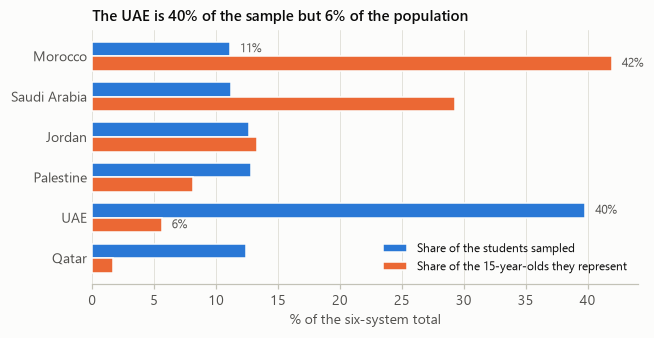

,students,schools,share_of_sample_%,population_15yo,share_of_population_%
QAT,7676,229,12.4,"18,347.7",1.7
ARE,24600,840,39.8,"60,764.9",5.6
PSE,7905,273,12.8,"88,383.2",8.2
JOR,7799,260,12.6,"144,268.9",13.3
SAU,6928,193,11.2,"317,451.6",29.3
MAR,6867,178,11.1,"454,986.4",42.0


In [2]:
sample_df = pd.DataFrame({
    "students": for_each_system(len),
    "schools": for_each_system(lambda system_df: system_df["CNTSCHID"].nunique()),
    "share_of_sample_%": for_each_system(len) / len(df) * 100,
    "population_15yo": for_each_system(lambda system_df: system_df["W_FSTUWT"].sum()),
})
sample_df["share_of_population_%"] = sample_df["population_15yo"] / sample_df["population_15yo"].sum() * 100
sample_df = sample_df.sort_values("share_of_population_%")
sample_df.to_csv(OUTPUT_DIR / "01_sample_vs_population.csv")

fig, ax = plt.subplots(figsize=(6.4, 3.0))
y_positions = np.arange(len(sample_df))
bar_height = 0.36
ax.barh(y_positions + bar_height / 2, sample_df["share_of_sample_%"], height=bar_height, color=BLUE,
        edgecolor=BACKGROUND_COLOR, linewidth=1, label="Share of the students sampled")
ax.barh(y_positions - bar_height / 2, sample_df["share_of_population_%"], height=bar_height, color=ORANGE,
        edgecolor=BACKGROUND_COLOR, linewidth=1, label="Share of the 15-year-olds they represent")
ax.set_yticks(y_positions, [NAME_BY_SYSTEM[system] for system in sample_df.index])
ax.set_xlabel("% of the six-system total")
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
for system in ["ARE", "MAR"]:   # label only the two extremes
    row_idx = list(sample_df.index).index(system)
    pct_sample = sample_df.loc[system, "share_of_sample_%"]
    pct_population = sample_df.loc[system, "share_of_population_%"]
    ax.text(pct_sample + 0.8, row_idx + bar_height / 2, f"{pct_sample:.0f}%", va="center", fontsize=8, color=SOFT_TEXT_COLOR)
    ax.text(pct_population + 0.8, row_idx - bar_height / 2, f"{pct_population:.0f}%", va="center", fontsize=8, color=SOFT_TEXT_COLOR)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("The UAE is 40% of the sample but 6% of the population")
save_figure(fig, "01_sample_vs_population")
plt.show()
sample_df.round(1)

**So what.** Unweighted numbers would mostly describe the UAE. Every statistic in this notebook is weighted.
For the models, this is the open weight question: population weights (`W_FSTUWT`) make the model mostly about Morocco and Saudi Arabia, while `SENWT` treats the six systems equally.

## 2. The target: maths scores and the Level 2 line

The histograms show how maths scores are spread in each system. All 10 plausible values are used, each with a tenth of the student's weight.
The vertical line is the Level 2 cut-off (420 points). Everything to its left counts as "below Level 2", the class we want to flag.

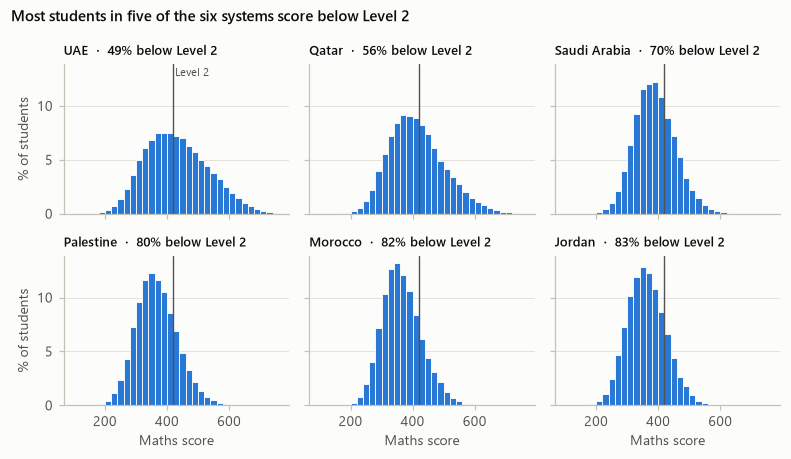

Pooled % below Level 2:
  population weight W_FSTUWT : 76.0
  equal per system SENWT     : 70.0
  unweighted rows            : 63.9



,mean,sd,p10,median,p90,pct_below_L2
ARE,431.1,101.4,306.2,422.8,570.2,49.0
QAT,414.1,88.8,307.2,405.4,535.8,56.5
SAU,388.8,65.6,308.3,385.0,474.4,70.0
PSE,365.7,65.9,285.4,361.4,452.3,79.9
MAR,364.8,62.7,289.1,359.3,449.4,81.6
JOR,361.2,61.7,283.6,358.4,442.0,82.8


In [3]:
def weighted_sd_over_pvs(system_df: pd.DataFrame) -> float:
    """Weighted standard deviation of the maths score, averaged over the 10 plausible values."""
    weights = system_df["W_FSTUWT"]
    sds = []
    for pv_col in PV_COLS:
        scores = system_df[pv_col]
        mean = np.average(scores, weights=weights)
        sds.append(np.sqrt(np.average((scores - mean) ** 2, weights=weights)))
    return np.mean(sds)

def weighted_quantile_over_pvs(system_df: pd.DataFrame, q: float) -> float:
    """Weighted quantile q of the maths score, averaged over the 10 plausible values."""
    return np.mean([weighted_quantile(system_df[pv_col], system_df["W_FSTUWT"], q) for pv_col in PV_COLS])

mean_score_by_system = for_each_system(lambda system_df: weighted_mean_over_pvs(system_df, PV_COLS))
systems_best_first = list(mean_score_by_system.sort_values(ascending=False).index)
score_bins = np.arange(100, 761, 20)

fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.2), sharex=True, sharey=True)
for ax, system in zip(axes.flat, systems_best_first):
    system_df = df_by_system[system]
    all_scores = np.concatenate([system_df[pv_col].to_numpy() for pv_col in PV_COLS])   # 10 scores per student
    all_weights = np.tile(system_df["W_FSTUWT"].to_numpy(), len(PV_COLS))              # each weight repeated 10 times
    ax.hist(all_scores, bins=score_bins, weights=all_weights / all_weights.sum() * 100,
            color=BLUE, edgecolor=BACKGROUND_COLOR, linewidth=0.6)
    ax.axvline(LEVEL2_CUTOFF, color=SOFT_TEXT_COLOR, linewidth=0.9)
    pct_below = weighted_mean_over_pvs(system_df, BELOW_L2_COLS) * 100
    ax.set_title(f"{NAME_BY_SYSTEM[system]}  ·  {pct_below:.0f}% below Level 2", fontsize=8.5)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
axes[0, 0].text(LEVEL2_CUTOFF + 6, axes[0, 0].get_ylim()[1] * 0.92, "Level 2", fontsize=7.5, color=SOFT_TEXT_COLOR)
for ax in axes[1]:
    ax.set_xlabel("Maths score")
for ax in axes[:, 0]:
    ax.set_ylabel("% of students")
fig.suptitle("Most students in five of the six systems score below Level 2", x=0.01, ha="left",
             fontsize=10, fontweight="semibold")
fig.tight_layout()
save_figure(fig, "02_maths_distributions")
plt.show()

maths_df = pd.DataFrame({
    "mean": mean_score_by_system,
    "sd": for_each_system(weighted_sd_over_pvs),
    "p10": for_each_system(lambda system_df: weighted_quantile_over_pvs(system_df, .10)),
    "median": for_each_system(lambda system_df: weighted_quantile_over_pvs(system_df, .50)),
    "p90": for_each_system(lambda system_df: weighted_quantile_over_pvs(system_df, .90)),
    "pct_below_L2": for_each_system(lambda system_df: weighted_mean_over_pvs(system_df, BELOW_L2_COLS) * 100),
}).loc[systems_best_first]
maths_df.to_csv(OUTPUT_DIR / "02_maths_by_system.csv")
print("Pooled % below Level 2:")
print(f"  population weight W_FSTUWT : {weighted_mean_over_pvs(df, BELOW_L2_COLS) * 100:.1f}")
print(f"  equal per system SENWT     : {weighted_mean_over_pvs(df, BELOW_L2_COLS, 'SENWT') * 100:.1f}")
print(f"  unweighted rows            : {df[BELOW_L2_COLS].to_numpy().mean() * 100:.1f}\n")
maths_df

**So what.**
- **The class we want to flag is the majority.** About three in four students (population-weighted) are below Level 2. A model that predicts "below" for everyone gets about 76% accuracy without learning anything.
  So we judge models with **ROC-AUC** (doesn't depend on the class balance), **balanced accuracy** and **recall for both classes**, not plain accuracy.
- **Systems differ a lot.** Averages range from about 360 to 430 points, and the share below Level 2 from about half to over 80%.
  If country is given to the model as a feature, part of its accuracy will just be "which country is this?". That is why results should also be reported **within each system**.

## 3. Missing values by system

Darker blue means more missing. Cells at 15% or more carry their number.

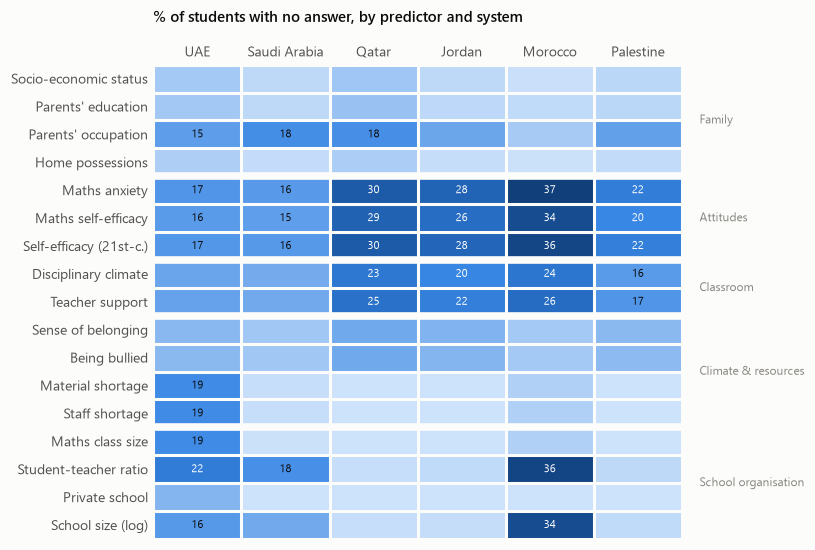

,UAE,Saudi Arabia,Qatar,Jordan,Morocco,Palestine
Socio-economic status,5.7,2.0,6.5,2.1,0.5,2.6
Parents' education,5.8,2.2,7.3,2.3,1.8,2.6
Parents' occupation,15.3,18.4,18.2,13.5,5.4,14.6
Home possessions,4.5,1.4,4.6,0.9,0.2,1.6
Maths anxiety,16.9,16.1,30.4,28.3,37.4,22.0
Maths self-efficacy,15.8,15.0,28.5,25.8,33.9,19.9
Self-efficacy (21st-c.),16.6,16.2,30.2,27.6,35.5,21.8
Disciplinary climate,13.6,12.3,23.3,20.1,23.8,15.9
Teacher support,14.3,12.7,24.8,21.8,26.1,17.0
Sense of belonging,9.5,6.1,13.0,10.7,5.7,9.3


In [4]:
# one row per predictor, one column per system
pct_missing_df = pd.DataFrame({NAME_BY_SYSTEM[system]: df_by_system[system][FEATURE_COLS].isna().mean() * 100
                               for system in SYSTEMS})
pct_missing_df.index = [LABEL_BY_FEATURE[feature] for feature in FEATURE_COLS]
pct_missing_df.to_csv(OUTPUT_DIR / "03_missing_by_system.csv")

fig, ax = plt.subplots(figsize=(6.2, 5.6))
draw_heatmap(ax, pct_missing_df, BLUES_CMAP, 0, 40,
             format_label=lambda value: f"{value:.0f}", should_label=lambda value: value >= 15)
draw_group_breaks(ax, label_x=pct_missing_df.shape[1] - 0.3)
ax.set_title("% of students with no answer, by predictor and system", pad=28)
save_figure(fig, "03_missing_by_system")
plt.show()
pct_missing_df

**So what.**
- **Maths attitudes** (15-37% missing) and **classroom climate and teacher support** (12-26%) are the most often skipped, worst in Morocco, Qatar and Jordan.
  **Parents' occupation** is also missing for 5-18% of students.
- **School variables** are almost complete in Qatar, Jordan and Palestine. They are missing for about 19% of UAE students (schools that didn't return the questionnaire),
  and the student-teacher ratio and school size are missing for about a third in Morocco and 13-18% in Saudi Arabia, partly because of the implausible values removed in Part A.
- No single system is "clean", so dropping incomplete rows is not an option. Imputation plus missing indicators (Part B) it is.

## 4. Is "missing" itself a signal?

For each predictor and system, we compare the average maths score of students who **left it blank** with those who **answered**, then average that gap over the systems.
Systems where fewer than 30 students skipped a question are left out of the average. A big gap, either way, means the blank tells the model something.
The chart shows predictors with enough missing values in at least three systems; the table has all of them.

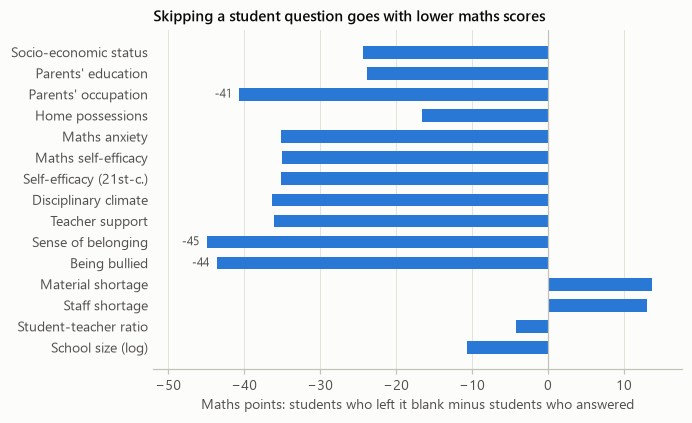

,ARE,SAU,QAT,JOR,MAR,PSE,average,systems_used
ESCS,-43.0,-13.0,-33.0,-19.0,-22.0,-17.0,-24.0,6
PAREDINT,-41.0,-14.0,-30.0,-20.0,-23.0,-15.0,-24.0,6
HISEI,-72.0,-27.0,-49.0,-41.0,-20.0,-35.0,-41.0,6
HOMEPOS,-38.0,-9.0,-22.0,-11.0,NaN,-3.0,-17.0,5
ANXMAT,-62.0,-22.0,-51.0,-28.0,-18.0,-29.0,-35.0,6
MATHEFF,-61.0,-23.0,-52.0,-28.0,-20.0,-26.0,-35.0,6
MATHEF21,-60.0,-23.0,-51.0,-29.0,-19.0,-29.0,-35.0,6
DISCLIM,-61.0,-26.0,-51.0,-28.0,-23.0,-29.0,-36.0,6
TEACHSUP,-62.0,-24.0,-51.0,-28.0,-22.0,-29.0,-36.0,6
BELONG,-62.0,-30.0,-56.0,-39.0,-46.0,-37.0,-45.0,6


In [5]:
def missing_score_gap(system_df: pd.DataFrame, feature: str) -> float:
    """Maths points: students who left feature blank minus students who answered it (NaN if fewer than 30 on either side)."""
    is_missing = system_df[feature].isna()
    if is_missing.sum() < 30 or (~is_missing).sum() < 30:
        return np.nan
    weights = system_df["W_FSTUWT"]
    return np.mean([np.average(system_df.loc[is_missing, pv_col], weights=weights[is_missing])
                    - np.average(system_df.loc[~is_missing, pv_col], weights=weights[~is_missing])
                    for pv_col in PV_COLS])

# one row per predictor, one column per system
gap_df = pd.DataFrame({system: {feature: missing_score_gap(df_by_system[system], feature) for feature in FEATURE_COLS}
                       for system in SYSTEMS})
gap_df["average"] = gap_df[SYSTEMS].mean(axis=1)
gap_df["systems_used"] = gap_df[SYSTEMS].notna().sum(axis=1)
gap_df.to_csv(OUTPUT_DIR / "04_missing_score_gap.csv")

avg_gap_by_feature = gap_df.loc[gap_df["systems_used"] >= 3, "average"]
fig, ax = plt.subplots(figsize=(6.2, 4.0))
y_positions = np.arange(len(avg_gap_by_feature))[::-1]
ax.barh(y_positions, avg_gap_by_feature, height=0.6, color=BLUE)
ax.axvline(0, color=AXIS_COLOR, linewidth=0.8)
ax.set_yticks(y_positions, [LABEL_BY_FEATURE[feature] for feature in avg_gap_by_feature.index])
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_xlim(min(avg_gap_by_feature.min() - 7, 0), max(avg_gap_by_feature.max() + 4, 0))   # room for the end labels
ax.set_xlabel("Maths points: students who left it blank minus students who answered")
for feature in avg_gap_by_feature.abs().nlargest(3).index:   # label only the three biggest gaps
    gap = avg_gap_by_feature[feature]
    y_pos = y_positions[list(avg_gap_by_feature.index).index(feature)]
    ax.text(gap - 1 if gap < 0 else gap + 1, y_pos, f"{gap:.0f}", ha="right" if gap < 0 else "left",
            va="center", fontsize=8, color=SOFT_TEXT_COLOR)
ax.set_title("Skipping a student question goes with lower maths scores")
save_figure(fig, "04_missing_score_gap")
plt.show()
gap_df.round(0)

**So what.**
- For **every student-questionnaire predictor, in every system with enough blanks to compare**, students who left it blank score lower: by 17 to 45 points on average, and by up to 72 points in the UAE.
- **School variables behave differently.** In the UAE, students whose school sent no questionnaire score *higher* than the rest (about 20-30 points). The data doesn't show why.
  Either way, missing school data is informative too.
- So the missing indicators made in Part A carry real information and belong in the models. In the ablations they must be removed **together with their group**.

## 5. What each predictor looks like

One histogram per predictor, all six systems pooled with equal weight (`SENWT`).
This is where we check shape: symmetric or skewed, smooth or lumpy, any values piled up at one end.

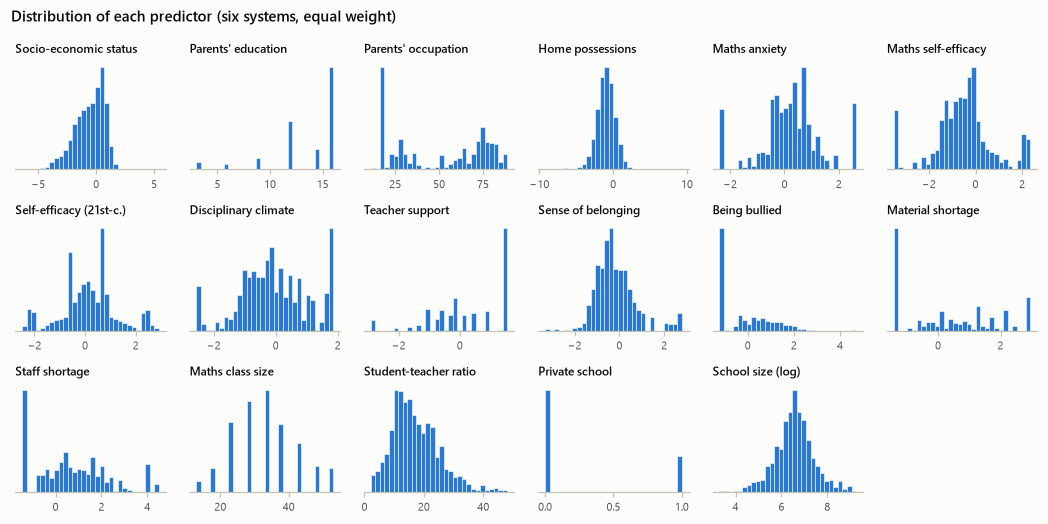

,mean,skewness,share_at_min_%,share_at_max_%
Socio-economic status,-0.6,-0.8,0.0,0.0
Parents' education,13.6,-1.9,2.8,59.2
Parents' occupation,50.6,-0.4,0.1,0.1
Home possessions,-1.0,0.1,0.0,0.0
Maths anxiety,0.2,-0.1,1.1,1.2
Maths self-efficacy,-0.5,-0.1,0.0,0.1
Self-efficacy (21st-c.),0.1,-0.0,0.0,0.0
Disciplinary climate,-0.0,-0.1,0.0,0.5
Teacher support,0.3,-0.6,3.8,34.9
Sense of belonging,-0.2,1.0,0.0,0.0


In [6]:
fig, axes = plt.subplots(3, 6, figsize=(9.6, 4.8))
for ax, feature in zip(axes.flat, FEATURE_COLS):
    values, weights = df[feature], df["SENWT"]
    is_present = values.notna()
    ax.hist(values[is_present], bins=30, weights=weights[is_present] / weights[is_present].sum() * 100,
            color=BLUE, edgecolor=BACKGROUND_COLOR, linewidth=0.4)
    ax.set_title(LABEL_BY_FEATURE[feature], fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
axes.flat[-1].axis("off")   # 17 predictors, 18 panels: hide the last one
fig.suptitle("Distribution of each predictor (six systems, equal weight)", x=0.01, ha="left", fontsize=10, fontweight="semibold")
fig.tight_layout()
save_figure(fig, "05_feature_distributions")
plt.show()

shape_df = pd.DataFrame({
    "mean": {feature: np.average(df[feature].dropna(), weights=df.loc[df[feature].notna(), "SENWT"])
             for feature in FEATURE_COLS},
    "skewness": df[FEATURE_COLS].skew(),
    "share_at_min_%": {feature: (df[feature] == df[feature].min()).sum() / df[feature].notna().sum() * 100
                       for feature in FEATURE_COLS},
    "share_at_max_%": {feature: (df[feature] == df[feature].max()).sum() / df[feature].notna().sum() * 100
                       for feature in FEATURE_COLS},
})
shape_df.index = [LABEL_BY_FEATURE[feature] for feature in FEATURE_COLS]
shape_df.to_csv(OUTPUT_DIR / "05_feature_shape.csv")
shape_df

**So what.** The questionnaire indices are lumpy. They are built from a handful of 4-point answers, so many students share exactly the same value, and several pile up at one end:
- 43% of students are at the minimum of *being bullied* (never bullied),
- 35% are at the maximum of *teacher support*,
- 37% are at the minimum of *material shortage* (the principal reported no shortage),
- 59% are at the top of *parents' education* (16 years, a university degree).

That is how these scales are built, and it needs no fixing. But it does mean these predictors can't tell apart the students inside each pile.
Tree models handle the lumps as they are; linear models and the MLP get in-fold scaling and clipping in Part B.

## 6. How the predictors relate to each other

A **correlation** (r) measures how strongly two variables move together, from -1 (opposite) through 0 (unrelated) to +1 (together).
Blue means positive and red negative; numbers are shown where |r| ≥ 0.3. Pooled across the six systems with equal weight.

Why it matters: when two predictors carry the same information (**collinearity**), linear models can't tell which one matters,
naive Bayes counts the same evidence twice, and removing one barely changes the result.

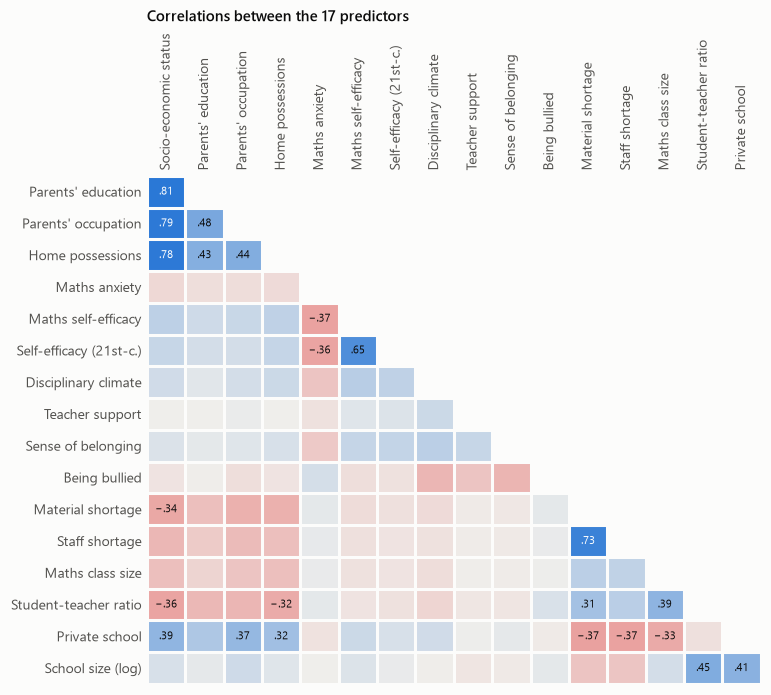

,predictor,with,r
1,ESCS,PAREDINT,0.8
2,ESCS,HISEI,0.8
3,ESCS,HOMEPOS,0.8
199,EDUSHORT,STAFFSHORT,0.7
91,MATHEFF,MATHEF21,0.7
19,PAREDINT,HISEI,0.5
254,STRATIO,SCHSIZE_log,0.5
37,HISEI,HOMEPOS,0.4
20,PAREDINT,HOMEPOS,0.4
271,SCHL_PRIVATE,SCHSIZE_log,0.4


In [7]:
corr_df = pd.DataFrame(index=FEATURE_COLS, columns=FEATURE_COLS, dtype=float)   # 17 x 17
for row_idx, feature_a in enumerate(FEATURE_COLS):
    for feature_b in FEATURE_COLS[:row_idx + 1]:
        corr_df.loc[feature_a, feature_b] = corr_df.loc[feature_b, feature_a] = (
            1.0 if feature_a == feature_b else weighted_corr(df[feature_a], df[feature_b], df["SENWT"]))
corr_df.to_csv(OUTPUT_DIR / "06_feature_correlations.csv")

is_below_diagonal = np.tril(np.ones(corr_df.shape, dtype=bool), k=-1)
lower_corr_df = corr_df.where(is_below_diagonal).iloc[1:, :-1]   # drop the empty first row / last column
lower_corr_df.index = [LABEL_BY_FEATURE[feature] for feature in lower_corr_df.index]
lower_corr_df.columns = [LABEL_BY_FEATURE[feature] for feature in lower_corr_df.columns]
fig, ax = plt.subplots(figsize=(7.2, 6.0))
draw_heatmap(ax, lower_corr_df, RED_BLUE_CMAP, -0.8, 0.8,
             format_label=format_r, should_label=lambda value: abs(value) >= 0.3)
ax.set_xticklabels(lower_corr_df.columns, rotation=90)
ax.set_title("Correlations between the 17 predictors", pad=8)
save_figure(fig, "06_feature_correlations")
plt.show()

is_above_diagonal = np.triu(np.ones(corr_df.shape, dtype=bool), k=1)
top_pairs_df = (corr_df.where(is_above_diagonal).stack().rename("r").reset_index()
                .assign(abs_r=lambda pairs_df: pairs_df["r"].abs())
                .sort_values("abs_r", ascending=False).head(10))
top_pairs_df[["level_0", "level_1", "r"]].rename(columns={"level_0": "predictor", "level_1": "with"}).round(2)

**So what.**
- The **family group overlaps strongly by design.** ESCS correlates about 0.8 with each of parents' education, parents' occupation and home possessions, because it is built *from* them.
  For the ablation (adding or removing the whole group) that is fine. For reading individual coefficients in a linear model, or for naive Bayes, it is not, and the report should say so.
  One option is to model family background either as ESCS alone or as its three parts, not both.
- The two **self-efficacy** scales go together (0.65), and both run moderately opposite to maths anxiety (about -0.37).
- **Material and staff shortage** are strongly linked (0.73).
- **School variables hang together.** Private schools have richer students (0.39 with ESCS), are larger and report fewer shortages, and larger schools have more students per teacher (0.45).
- Most pairs *across* groups are weak, so each group brings mostly different information.

## 7. Which predictors go with maths scores?

Correlation of each predictor with the maths score, **within each system** (averaged over the 10 plausible values), plus the average across systems.
Working within each system shows whether a predictor works the same way everywhere, which matters for "one general model" across six systems.
Numbers are shown where |r| ≥ 0.15.

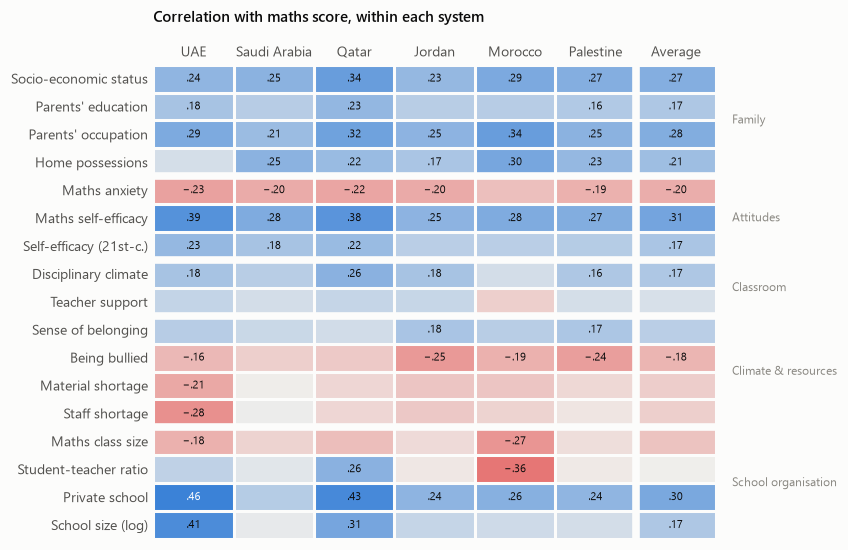

,strongest predictor,its average r
Family,Parents' occupation,0.3
Attitudes,Maths self-efficacy,0.3
Classroom,Disciplinary climate,0.2
Climate & resources,Being bullied,-0.2
School organisation,Private school,0.3


In [8]:
def maths_corr(system_df: pd.DataFrame, feature: str) -> float:
    """Weighted correlation of feature with the maths score, averaged over the 10 plausible values."""
    return np.mean([weighted_corr(system_df[feature], system_df[pv_col], system_df["W_FSTUWT"]) for pv_col in PV_COLS])

# one row per predictor, one column per system, plus the average
maths_corr_df = pd.DataFrame({NAME_BY_SYSTEM[system]: {feature: maths_corr(df_by_system[system], feature)
                                                       for feature in FEATURE_COLS}
                              for system in SYSTEMS})
maths_corr_df["Average"] = maths_corr_df.mean(axis=1)
maths_corr_df.to_csv(OUTPUT_DIR / "07_feature_maths_correlations.csv")

labelled_corr_df = maths_corr_df.copy()
labelled_corr_df.index = [LABEL_BY_FEATURE[feature] for feature in FEATURE_COLS]
fig, ax = plt.subplots(figsize=(6.6, 5.6))
draw_heatmap(ax, labelled_corr_df, RED_BLUE_CMAP, -0.5, 0.5,
             format_label=format_r, should_label=lambda value: abs(value) >= 0.15)
ax.axvline(len(SYSTEMS) - 0.5, color=BACKGROUND_COLOR, linewidth=5)   # gap before the Average column
draw_group_breaks(ax, label_x=labelled_corr_df.shape[1] - 0.3)
ax.set_title("Correlation with maths score, within each system", pad=28)
save_figure(fig, "07_feature_maths_correlations")
plt.show()

strongest_feature_by_group = {group: maths_corr_df.loc[group_cols, "Average"].abs().idxmax()
                              for group, group_cols in FEATURES_BY_GROUP.items()}
strongest_by_group_df = pd.DataFrame({
    "strongest predictor": {group: LABEL_BY_FEATURE[feature] for group, feature in strongest_feature_by_group.items()},
    "its average r": {group: maths_corr_df.loc[feature, "Average"] for group, feature in strongest_feature_by_group.items()},
})
strongest_by_group_df.index = [LABEL_BY_GROUP[group] for group in strongest_by_group_df.index]
strongest_by_group_df.round(2)

**So what.**
- **The strongest single links (r ≈ 0.3)** are maths self-efficacy (how confident students feel doing maths tasks), private schooling, parents' occupation and ESCS.
  Self-efficacy and the family predictors work much the same way in all six systems, and so does maths anxiety (about -0.2).
- **School-level factors matter mostly in the UAE and Qatar**, which have large private sectors.
  There, private schooling (0.46 / 0.43) and school size (0.41 / 0.31) are among the strongest predictors; elsewhere school size is close to zero.
- **Some predictors point in opposite directions in different systems.** A higher student-teacher ratio goes with *higher* scores in Qatar (+0.26) but *lower* scores in Morocco (-0.36).
  Teacher support is slightly negative only in Morocco. A single pooled model averages such differences away. This is a reason to report results per system, and a point for the Discussion.
- **All links are modest** (|r| at most 0.46), so no predictor explains much on its own. How much a group adds *on top of* the others is what the ablations measure.

## 8. Low achievement by socio-economic status

Students are split into four equal groups (**quartiles**) by ESCS *within their own system*: Q1 is the poorest quarter, Q4 the richest.
Each panel highlights one system (blue) with the other five in grey for comparison.

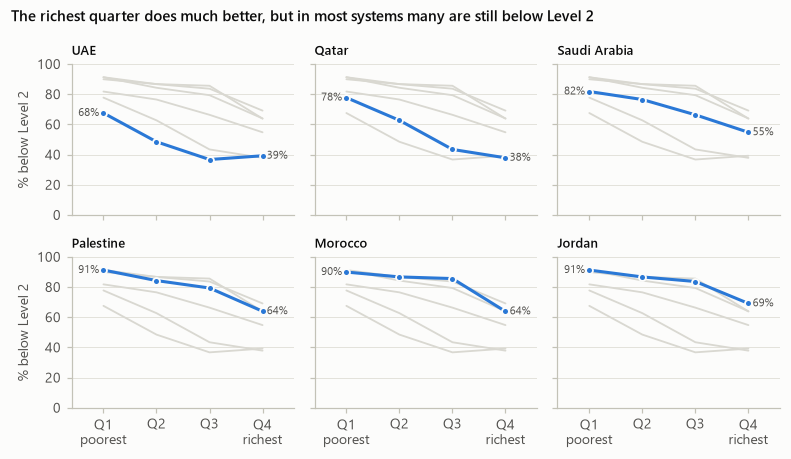

Q1   Q2   Q3   Q4
predictor CNT                    
ESCS      ARE 68.0 48.0 37.0 39.0
          SAU 82.0 76.0 66.0 55.0
          QAT 78.0 63.0 43.0 38.0
          JOR 91.0 87.0 84.0 69.0
          MAR 90.0 87.0 86.0 64.0
          PSE 91.0 84.0 79.0 64.0
MATHEFF   ARE 68.0 47.0 41.0 24.0
          SAU 84.0 72.0 64.0 53.0
          QAT 75.0 49.0 47.0 28.0
          JOR 90.0 85.0 78.0 68.0
          MAR 90.0 86.0 77.0 61.0
          PSE 90.0 84.0 76.0 62.0
ANXMAT    ARE 33.0 39.0 49.0 55.0
          SAU 56.0 65.0 72.0 79.0
          QAT 38.0 43.0 55.0 62.0
          JOR 70.0 77.0 83.0 88.0
          MAR 72.0 75.0 80.0 85.0
          PSE 68.0 74.0 81.0 85.0

In [9]:
def pct_below_by_quartile(system_df: pd.DataFrame, feature: str) -> pd.Series:
    """% below Level 2 in each quarter of feature (Q1 = lowest quarter), within one system."""
    system_df = system_df[system_df[feature].notna()]
    weights = system_df["W_FSTUWT"]
    cut_points = [weighted_quantile(system_df[feature], weights, q) for q in (.25, .5, .75)]
    quartile_of_each_student = np.digitize(system_df[feature], cut_points)   # 0, 1, 2 or 3 for each student
    pct_by_quartile = {}
    for quartile in range(4):
        is_in_quartile = quartile_of_each_student == quartile
        pct_by_quartile[f"Q{quartile + 1}"] = (
            np.mean([np.average(system_df[below_col][is_in_quartile], weights=weights[is_in_quartile])
                     for below_col in BELOW_L2_COLS]) * 100
            if is_in_quartile.any() else np.nan)
    return pd.Series(pct_by_quartile)

# predictor -> table with one row per system and columns Q1-Q4
gradient_df_by_feature = {feature: pd.DataFrame({system: pct_below_by_quartile(df_by_system[system], feature)
                                                 for system in SYSTEMS}).T
                          for feature in ["ESCS", "MATHEFF", "ANXMAT"]}
pd.concat(gradient_df_by_feature, names=["predictor", "CNT"]).to_csv(OUTPUT_DIR / "08_below_L2_by_quartile.csv")

escs_gradient_df = gradient_df_by_feature["ESCS"]
fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.2), sharex=True, sharey=True)
x_positions = np.arange(4)
for ax, system in zip(axes.flat, systems_best_first):
    for other_system in SYSTEMS:
        if other_system != system:
            ax.plot(x_positions, escs_gradient_df.loc[other_system], color=CONTEXT_COLOR, linewidth=1.2, zorder=1)
    ax.plot(x_positions, escs_gradient_df.loc[system], color=BLUE, linewidth=2, zorder=3, marker="o", markersize=4.5,
            markeredgecolor=BACKGROUND_COLOR, markeredgewidth=1.2)
    pct_q1, pct_q4 = escs_gradient_df.loc[system, "Q1"], escs_gradient_df.loc[system, "Q4"]
    ax.text(3.08, pct_q4, f"{pct_q4:.0f}%", va="center", fontsize=7.5, color=SOFT_TEXT_COLOR)
    ax.text(-0.08, pct_q1, f"{pct_q1:.0f}%", va="center", ha="right", fontsize=7.5, color=SOFT_TEXT_COLOR)
    ax.set_title(NAME_BY_SYSTEM[system], fontsize=8.5)
    ax.set_xticks(x_positions, ["Q1\npoorest", "Q2", "Q3", "Q4\nrichest"])
    ax.set_ylim(0, 100)
    ax.set_xlim(-0.6, 3.6)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel("% below Level 2")
fig.suptitle("The richest quarter does much better, but in most systems many are still below Level 2",
             x=0.01, ha="left", fontsize=10, fontweight="semibold")
fig.tight_layout()
save_figure(fig, "08_below_L2_by_escs")
plt.show()
pd.concat(gradient_df_by_feature, names=["predictor", "CNT"]).round(0)

**So what.**
- In every system, the share below Level 2 falls from the poorest to the richest quarter, by 22-40 points. That is why home background alone already predicts well.
- The shape differs. In the UAE the curve flattens at the top (Q3 and Q4 are about the same).
  In Jordan, Morocco and Palestine the first three quarters all sit around 80-90%, and only the richest quarter does clearly better.
- Even in the richest quarter, more than half the students are below Level 2 in four of the six systems, so home background is far from the whole story.
- In the table, **maths self-efficacy** shows a gradient at least as steep (UAE: 68% → 24% from least to most confident).
  **Maths anxiety** runs the other way: the more anxious the quarter, the more students are below Level 2.

## 9. How much do schools differ?

The share of the maths-score variation that lies **between schools** (school averages differ) rather than **within schools** (students in the same school differ).
Computed as the weighted variance of school means divided by the total variance, averaged over the 10 plausible values.
This simple version slightly overstates the between-school share for small schools, so treat it as approximate.

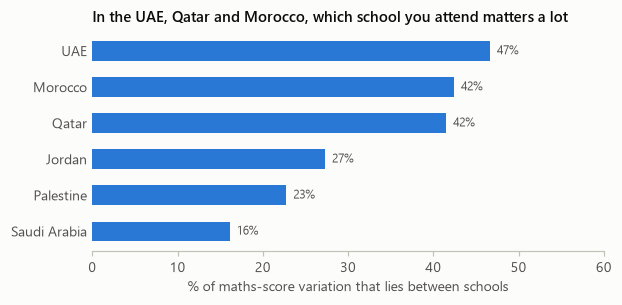

SAU   16.1
PSE   22.8
JOR   27.3
QAT   41.5
MAR   42.4
ARE   46.7
Name: between_school_%, dtype: float64

In [10]:
def pct_between_schools(system_df: pd.DataFrame) -> float:
    """% of the maths-score variance that lies between schools, averaged over the 10 plausible values."""
    weights = system_df["W_FSTUWT"]
    school_weights = weights.groupby(system_df["CNTSCHID"]).sum()   # total weight of each school
    shares = []
    for pv_col in PV_COLS:
        scores = system_df[pv_col]
        overall_mean = np.average(scores, weights=weights)
        school_means = (scores * weights).groupby(system_df["CNTSCHID"]).sum() / school_weights
        shares.append(np.average((school_means - overall_mean) ** 2, weights=school_weights)
                      / np.average((scores - overall_mean) ** 2, weights=weights))
    return np.mean(shares) * 100

pct_between_by_system = for_each_system(pct_between_schools).rename("between_school_%").sort_values()
pct_between_by_system.to_csv(OUTPUT_DIR / "09_between_school_share.csv")
fig, ax = plt.subplots(figsize=(6.0, 2.6))
y_positions = np.arange(len(pct_between_by_system))
ax.barh(y_positions, pct_between_by_system, height=0.55, color=BLUE)
ax.set_yticks(y_positions, [NAME_BY_SYSTEM[system] for system in pct_between_by_system.index])
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
for row_idx, pct in enumerate(pct_between_by_system):
    ax.text(pct + 0.8, row_idx, f"{pct:.0f}%", va="center", fontsize=8, color=SOFT_TEXT_COLOR)
ax.set_xlim(0, 60)
ax.set_xlabel("% of maths-score variation that lies between schools")
ax.set_title("In the UAE, Qatar and Morocco, which school you attend matters a lot")
save_figure(fig, "09_between_school_share")
plt.show()
pct_between_by_system.round(1)

**So what.** The figures match the between-school shares in the pre-project tour (`00_pre-project/outputs/country_summary.csv`) exactly.
Students in the same school are much more alike than students in different schools: in the UAE, Morocco and Qatar over 40% of all the variation lies between schools, against 16% in Saudi Arabia.
If the same school appeared in both training and test data, the model could partly "recognise" the school instead of learning general patterns, and the scores would look too good.
This is the evidence for the **school-grouped folds** in the plan. It also means school-level variables can only be judged on schools the model hasn't seen.

## 10. A first look at the side questions

Quick numbers only, to check the pitch's figures. The full analyses are separate tasks.
- **Digital distraction**: % of students distracted by their own devices in most or every maths lesson, and the share below Level 2 among distracted vs not distracted students.
- **Academic resilience**: among the poorest quarter of students (ESCS, within each system), the % who reach the top quarter in maths within their own system.

In [11]:
def distraction_stats(system_df: pd.DataFrame) -> pd.Series:
    """Digital-distraction percentages for one system."""
    has_answered = system_df["DISTRACTED_OWN"].notna()
    answered_df = system_df[has_answered]
    weights = answered_df["W_FSTUWT"]
    is_distracted = answered_df["DISTRACTED_OWN"] == 1
    return pd.Series({
        "answered_%": has_answered.mean() * 100,
        "distracted_%": np.average(is_distracted, weights=weights) * 100,
        "below_L2_if_distracted_%": np.mean([np.average(answered_df[below_col][is_distracted], weights=weights[is_distracted])
                                             for below_col in BELOW_L2_COLS]) * 100,
        "below_L2_if_not_%": np.mean([np.average(answered_df[below_col][~is_distracted], weights=weights[~is_distracted])
                                      for below_col in BELOW_L2_COLS]) * 100,
    })

def pct_resilient(system_df: pd.DataFrame) -> float:
    """% of the poorest quarter (by ESCS) who reach the top quarter in maths, within one system."""
    system_df = system_df[system_df["ESCS"].notna()]
    weights = system_df["W_FSTUWT"]
    is_poorest_quarter = system_df["ESCS"] <= weighted_quantile(system_df["ESCS"], weights, .25)
    return np.mean([np.average(system_df[pv_col][is_poorest_quarter] >= weighted_quantile(system_df[pv_col], weights, .75),
                               weights=weights[is_poorest_quarter])
                    for pv_col in PV_COLS]) * 100

side_questions_df = pd.DataFrame({system: distraction_stats(df_by_system[system]) for system in SYSTEMS}).T
side_questions_df["resilient_%"] = for_each_system(pct_resilient)
side_questions_df.index = [NAME_BY_SYSTEM[system] for system in side_questions_df.index]
side_questions_df.to_csv(OUTPUT_DIR / "10_side_questions.csv")
side_questions_df.round(1)

,answered_%,distracted_%,below_L2_if_distracted_%,below_L2_if_not_%,resilient_%
UAE,61.6,24.4,55.6,41.4,9.0
Saudi Arabia,62.4,19.2,79.0,65.9,14.1
Qatar,53.9,22.1,64.8,46.7,7.0
Jordan,55.8,27.9,89.4,77.1,14.4
Morocco,53.3,38.9,82.5,76.8,15.7
Palestine,59.5,25.9,87.8,74.7,12.1


**So what.**
- **Distraction.** 19-39% of students are distracted by their own devices in most or every lesson (Saudi Arabia lowest, Morocco highest), matching the pitch.
  Distracted students are more often below Level 2 in every system, by 6-18 points, before taking home background into account.
  But only 53-62% of students answered this question, so the distraction analysis runs on a smaller, possibly less typical, group.
- **Resilience.** 7-16% of the poorest quarter reach their system's top quarter (Qatar lowest, Morocco highest), in line with the pitch's 6-16%.

## Summary: what the EDA means for the next steps

| Finding | What we do about it |
|---|---|
| The UAE is 40% of the sample but 6% of the population | Always weight. The team must choose `W_FSTUWT` vs `SENWT` for the models |
| About 3 in 4 students are below Level 2 | Use ROC-AUC, balanced accuracy and recall for both classes, not accuracy alone |
| Systems differ by about 70 points on average | Report results within each system, not only pooled. Decide whether country is a feature |
| Up to 37% of answers missing, and skipping goes with lower scores | Keep every student. Impute inside the folds and keep the missing indicators, grouped with their factor group |
| The family predictors overlap heavily (ESCS is built from the other three) | Fine for group ablations. Be careful interpreting linear coefficients and naive Bayes |
| Self-efficacy, private schooling and family background have the strongest single links (r ≈ 0.3). School factors matter mainly in the UAE and Qatar, and some point in opposite directions across systems | Several groups should contribute; the ablations decide. Report per-system results and discuss the differences |
| Up to about half of the score variation lies between schools | School-grouped folds are essential, as planned |
| Indices are lumpy, and school size was very skewed | Already handled (log school size). Scale and clip inside the folds for linear models and the MLP |

Figures for the report are in `outputs/eda/figures/`, with the numbers behind each one in `outputs/eda/`.